# Chapter 3: Embeddings as features for prediction

**Theory 5 min, exercise 10 min, outlook 5 min.**

So far we compared embeddings with each other. The most common use in applied research is different: embed your texts, then feed the vectors into an ordinary statistical model as predictors. The language model never sees your labels. It only provides a rich numerical description of each text, and the statistics you already know do the rest.

## Theory

### Three ways to get a prediction out of a language model

![Feature extraction, changing the model head, and text generation](images/three_approaches.png)

Suppose you have texts and want a label or a score for each: a sentiment, a diagnosis category, a creativity rating. There are three routes.

1. **Feature extraction.** Embed the text, train any classical model on the vectors. The language model is frozen.
2. **Changing the model head.** Replace the model's output layer with a classifier and fine-tune part or all of the network on your labels. More powerful, more expensive, and the model can overfit a small dataset.
3. **Text generation.** Ask an instruction-tuned model, in words, to produce the label. No training data needed, but the output must be parsed, it is sensitive to the prompt, and it is hard to audit.

This chapter is about the first route. It is the cheapest, the most transparent, and surprisingly hard to beat when you have a few hundred labelled examples.

### Feature extraction in two steps

![Step 1 embed the inputs, step 2 train a predictive model on the embeddings](images/feature_extraction.png)

Step one turns N texts into an N by D matrix, with D equal to the embedding dimension (384 for the model we use, 768 for larger ones). Step two is any supervised method that takes a numeric matrix: ridge or lasso regression, logistic regression, random forests, gradient boosting. Because D is large relative to N in most psychology datasets, a **penalised** linear model is the sensible default, and that is what the exercise uses.

### Practical guide

Adapted from the course slide that compares the three approaches.

| | Feature extraction | Changing model head | Text generation |
|---|---|---|---|
| Training data needs | Moderate | Moderate to extreme | None to low |
| Computational needs | Low | Moderate to extreme | High to extreme |
| Biases | Moderate data and model bias | Strong data bias | Model bias |
| Performance | Very high (potentially) | Extremely high | Very high |
| Recommendation | Robust default with good training data | Top performance with good training data; prefer LoRA or adapters over full fine-tuning | Default without good training data |

### Which embedding model?

![Models differ in type and size; embedding models are the small, fast corner](images/model_landscape.png)

Embedding models are the small corner of the language model landscape: tens to hundreds of millions of parameters, not billions, which is why they run on a CPU. Within that corner there are hundreds of options. The [MTEB leaderboard](https://huggingface.co/spaces/mteb/leaderboard) benchmarks them across clustering, classification, retrieval and similarity tasks. For a project, start with a small general-purpose model, check whether a top-ranked model under 1B parameters helps, and only then consider fine-tuning on your own domain, as the personality model in Chapter 2 did.

![BERT-style models for feature extraction, GPT-style models for generation](images/course_models.png)

```{admonition} Check your understanding
:class: note
1. Why must the scaler be fitted on the training set only, and what would go wrong if it were fitted on all the data?
2. You have 150 labelled therapy transcripts. Which of the three routes would you try first, and why?
3. What does a ridge penalty do when there are 384 predictors and 1,000 observations?
```

## Exercise

Press the rocket at the top of the page and choose **Colab**, then run the cells in order.

We use a small dataset of tweets by US politicians labelled as `neutral` or `partisan`. The pattern is identical for any text you have labels for: open-ended survey responses coded for depression themes, therapy transcripts rated for alliance, essays scored for creativity.

### Setup

```{admonition} In the session and after it
:class: tip
Sections marked **Optional** will not fit into the live session. They are there for afterwards, and they run on the same Colab copy.
```

In [1]:
import sys
if 'google.colab' in sys.modules:
    !pip install -q sentence-transformers pacmap

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics.pairwise import cosine_similarity
from sentence_transformers import SentenceTransformer

# Data is read straight from the public course repository; nothing to upload or mount.
DATA = "https://raw.githubusercontent.com/dwulff/LLM4BeSci_2025MetaRep/main/day_2/"

# The embedding model used in this chapter. 22M parameters, 384 dimensions, fast on a CPU.
MODEL_NAME = "all-MiniLM-L6-v2"

model = SentenceTransformer(MODEL_NAME)
print("Loaded", MODEL_NAME, "with", model.get_sentence_embedding_dimension(), "dimensions")

Loaded all-MiniLM-L6-v2 with 384 dimensions


### 3.1 The data

In [2]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeClassifierCV

train = pd.read_csv(DATA + "media_bias_train.csv")
test = pd.read_csv(DATA + "media_bias_test.csv")
print(len(train), "training tweets,", len(test), "test tweets")
train[["text", "bias"]].head()

1200 training tweets, 100 test tweets


,text,bias
0,Excited to join @fairvote today @NYUWashington...,neutral
1,Placer reunirme c la directora de @NTN24 @CGur...,neutral
2,DID YOU KNOW: 73% of Americans want to #RaiseT...,neutral
3,.@meridianstar: http://t.co/gyjLbggc0t @GreggH...,neutral
4,".@AmericanLegion, @IAVA, @AMVETSNational, and ...",neutral


### 3.2 Embed, standardise, fit

Three steps. Ridge is a linear model with an L2 penalty, which assumes all features are on the same scale, hence the standardisation. The scaler is fitted on the training set only and then applied to the test set, so no information leaks from test to train.

In [3]:
# 1. Embed (about a minute on a CPU for 1,337 tweets)
train_x = model.encode(train["text"])
test_x = model.encode(test["text"])

# 2. Standardise (fit on train only)
scaler = StandardScaler().fit(train_x)
train_x, test_x = scaler.transform(train_x), scaler.transform(test_x)

# 3. Fit a penalised linear classifier; the penalty strength is chosen by cross-validation
ridge = RidgeClassifierCV(alphas=[1e-2, 1e-1, 1, 10, 100, 1000]).fit(train_x, train["bias"])

print(f"Train accuracy: {ridge.score(train_x, train['bias']):.2f}")
print(f"Test accuracy:  {ridge.score(test_x, test['bias']):.2f}   (chance = 0.50)")

Train accuracy: 0.80
Test accuracy:  0.76   (chance = 0.50)


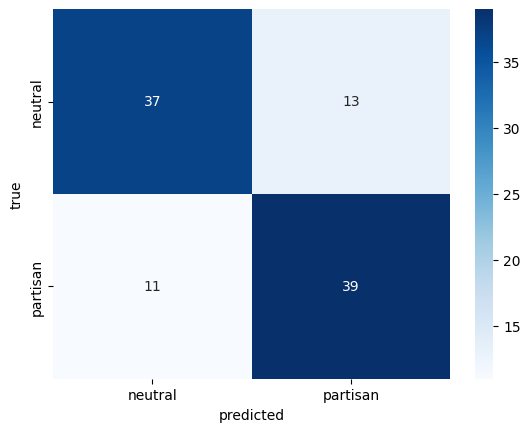

In [4]:
confusion = pd.crosstab(test["bias"], ridge.predict(test_x), rownames=["true"], colnames=["predicted"])
sns.heatmap(confusion, annot=True, fmt="d", cmap="Blues");

With a 22M-parameter model and a linear classifier we are well above chance on a subtle judgement, with no prompt engineering and in under a minute on a CPU. The labels are *partisan* (the tweet takes a political side) versus *neutral*.

### 3.3 You versus the model

How hard is this judgement for a person? The next cell shows ten test tweets without their labels. Read them, write your guesses into `my_guesses` in the cell after, and the notebook scores you and the model on the same ten.

In [5]:
sample = test.sample(10, random_state=1)
for i, text in enumerate(sample["text"]):
    print(f"{i}: {text}\n")

0: RT @WKBW Ohio Street Project Moves Forward http://t.co/T3vcwG8jZg

1: So what Dr. Lynch is saying is that the @DeptVetAffairs has the wrong goals. #LameExcuses #10 http://t.co/9iNMTfnW2a

2: Proud to receive @HDMAconnect's Bull Dog Award for my commitment to keeping our RX supply chain safe from counterfeit http://t.co/u9FSH4dlOt

3: @BarackObama's latest #Keystone delay hurts Montana jobs. No more excuses -- it's #TimeToBuild http://t.co/aEvKDFFwta

4: RT @AllDailyRepNews: Garamendi backs bills on flood rules, insurance rates http://t.co/AqGT69dw5F

5: New CBO report: increasing the minimum wage to $10.10 would raise wages for nearly 25 million Americans: http://t.co/2nlEv5y67S

6: The House will pass a bill to pay federal workers for their time in furlough once the shutdown ends.

7: I believe President Obama offered many common sense proposals to reducing gun violence. For example, background... http://t.co/g2xmO06E

8: .@TigernBham House DemsÛª #MakeItInAmerica plan is focused 

In [6]:
# Your guesses, one per tweet above, each "partisan" or "neutral"
my_guesses = ["?", "?", "?", "?", "?", "?", "?", "?", "?", "?"]

truth = sample["bias"].values
model_guesses = ridge.predict(test_x[sample.index])

scoreboard = pd.DataFrame({"tweet": sample["text"].str[:60].values, "truth": truth, "you": my_guesses, "model": model_guesses})
if "?" in my_guesses:
    print("Fill in my_guesses first. The model's score is shown already.")
else:
    print(f"You:   {(scoreboard['you'] == truth).mean():.1f}")
print(f"Model: {(scoreboard['model'] == truth).mean():.1f}")
scoreboard

Fill in my_guesses first. The model's score is shown already.
Model: 0.7


,tweet,truth,you,model
0,RT @WKBW Ohio Street Project Moves Forward htt...,partisan,?,partisan
1,So what Dr. Lynch is saying is that the @DeptV...,partisan,?,partisan
2,Proud to receive @HDMAconnect's Bull Dog Award...,neutral,?,neutral
3,@BarackObama's latest #Keystone delay hurts Mo...,partisan,?,partisan
4,RT @AllDailyRepNews: Garamendi backs bills on ...,partisan,?,partisan
5,New CBO report: increasing the minimum wage to...,neutral,?,partisan
6,The House will pass a bill to pay federal work...,neutral,?,partisan
7,I believe President Obama offered many common ...,partisan,?,partisan
8,.@TigernBham House DemsÛª #MakeItInAmerica pl...,partisan,?,partisan
9,Typical #SNAP household with kids has income o...,partisan,?,neutral


Most people land between .5 and .7 on these ten, and disagree with each other about which tweets are partisan. The labels were produced by a panel of raters and are not beyond dispute. That is worth remembering when a classifier scores .76: part of the remaining .24 is label noise, not model error.

### 3.4 Is .76 real, and how precise is it?

Two different questions, two resampling answers. A **permutation test** refits the classifier on shuffled labels to show what accuracy chance alone produces. A **bootstrap** resamples the test set to give a confidence interval around the observed accuracy.

Observed accuracy 0.76; largest accuracy under the null 0.68


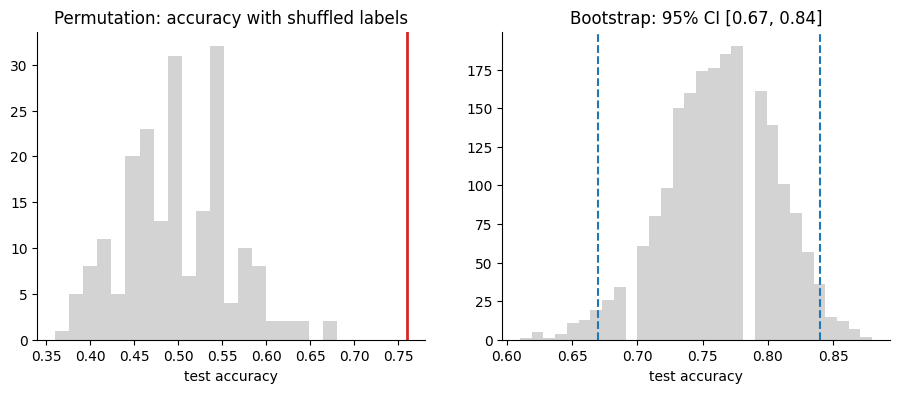

In [7]:
from sklearn.linear_model import RidgeClassifier

rng = np.random.default_rng(0)
observed_accuracy = ridge.score(test_x, test["bias"])

# Permutation: shuffle the training labels, refit with the penalty chosen above, score on the real test labels
null_accuracy = np.array([
    RidgeClassifier(alpha=ridge.alpha_).fit(train_x, rng.permutation(train["bias"].values)).score(test_x, test["bias"])
    for _ in range(200)
])

# Bootstrap: resample the test set with replacement and recompute the accuracy
correct = (ridge.predict(test_x) == test["bias"].values)
boot_accuracy = np.array([rng.choice(correct, size=len(correct)).mean() for _ in range(2000)])
ci_low, ci_high = np.percentile(boot_accuracy, [2.5, 97.5])

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(null_accuracy, bins=20, color="lightgrey")
axes[0].axvline(observed_accuracy, color="C3", linewidth=2)
axes[0].set_title("Permutation: accuracy with shuffled labels"); axes[0].set_xlabel("test accuracy")
axes[1].hist(boot_accuracy, bins=30, color="lightgrey")
axes[1].axvline(ci_low, color="C0", linestyle="--"); axes[1].axvline(ci_high, color="C0", linestyle="--")
axes[1].set_title(f"Bootstrap: 95% CI [{ci_low:.2f}, {ci_high:.2f}]"); axes[1].set_xlabel("test accuracy")
sns.despine()
print(f"Observed accuracy {observed_accuracy:.2f}; largest accuracy under the null {null_accuracy.max():.2f}")

**Task 1.** The confidence interval is wide because the test set has only 100 tweets. Move 400 tweets from `train` to `test` in 3.1, rerun, and watch both the interval and the point estimate. Which one changed more, and why?

### Optional: how much labelled data do you need?

The practical question for your own study. The cell refits the classifier on random subsets of the training set and plots test accuracy against training size.

training tweets
25      0.64
50      0.68
100     0.72
200     0.74
400     0.74
800     0.75
1200    0.76


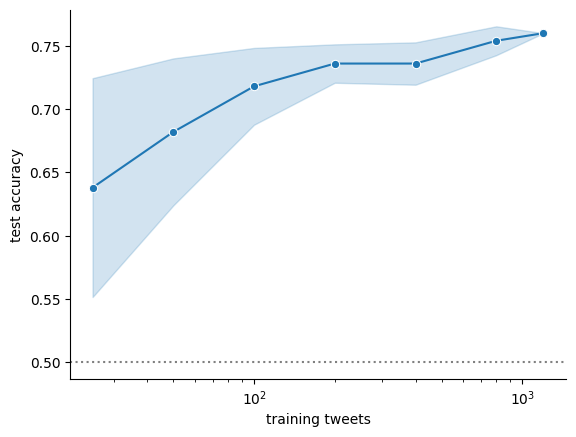

In [8]:
sizes = [25, 50, 100, 200, 400, 800, len(train)]
rng = np.random.default_rng(0)
curve = []
for n in sizes:
    for rep in range(5):
        idx = rng.choice(len(train), size=n, replace=False)
        acc = RidgeClassifier(alpha=ridge.alpha_).fit(train_x[idx], train["bias"].values[idx]).score(test_x, test["bias"])
        curve.append({"training tweets": n, "test accuracy": acc})
curve = pd.DataFrame(curve)

sns.lineplot(data=curve, x="training tweets", y="test accuracy", marker="o", errorbar="sd")
plt.xscale("log"); plt.axhline(0.5, color="grey", linestyle=":"); sns.despine()
print(curve.groupby("training tweets")["test accuracy"].mean().round(2).to_string())

**Optional task.** Where does the curve flatten? If each label costs you a minute of a rater's time, how many would you buy?

### Optional: the tweets on a map

The same two-dimensional map as in Chapter 2, now for the test tweets, coloured by their label. It shows why the accuracy is .76 and not .99: partisan and neutral tweets overlap heavily in embedding space, and the classifier draws the best straight line it can through that overlap.

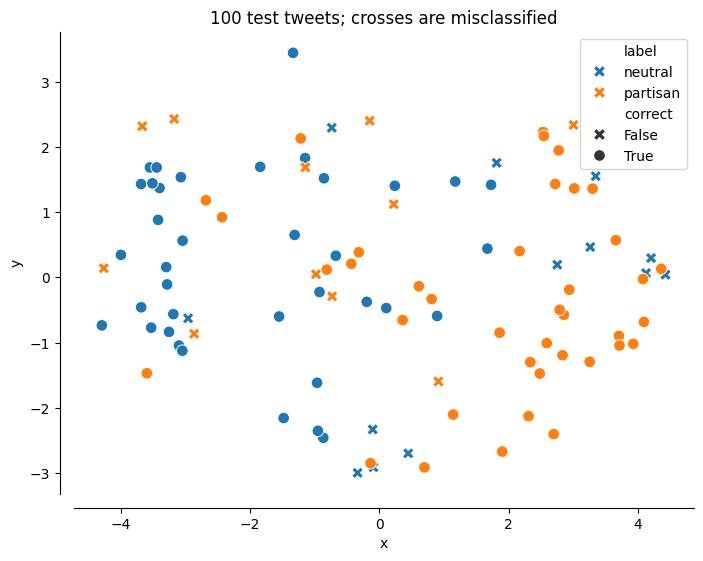

In [9]:
from pacmap import PaCMAP

xy = PaCMAP(n_components=2, random_state=42).fit_transform(test_x)
tweet_map = pd.DataFrame(xy, columns=["x", "y"])
tweet_map["label"] = test["bias"].values
tweet_map["correct"] = correct

plt.figure(figsize=(8, 6))
sns.scatterplot(data=tweet_map, x="x", y="y", hue="label", style="correct", markers={True: "o", False: "X"}, s=70)
sns.despine(offset=10)
plt.title("100 test tweets; crosses are misclassified");

**Task 2.** Open the [MTEB leaderboard](https://huggingface.co/spaces/mteb/leaderboard), pick a well-ranked model under 1B parameters whose card carries the `sentence-transformers` tag, put its name into `MODEL_NAME` in the Setup cell and rerun. Does a bigger embedding model help?

**Task 3.** Replace `RidgeClassifierCV` with `sklearn.linear_model.LogisticRegressionCV` or `sklearn.ensemble.RandomForestClassifier`. Does the choice of classical model matter much compared to the choice of embedding model?

## Outlook: what embeddings enable in the field

![Four uses of embeddings for qualitative data](images/applications.png)

Prediction is one use. Because embeddings turn any text into a point in a shared space, the same vectors support four families of analysis.

**Map and cluster.** Embed every abstract in a literature, reduce to two dimensions, and the field's structure becomes visible. Below, 5,692 reinforcement-learning articles, with the articles matching each topic highlighted.

![Core and peripheral topics in reinforcement learning research](images/map_rl.png)

The same works for participant-generated text. Here, free associations to the word *AI* cluster into technology, benefits, worries and job loss, and the clusters relate to expertise and trust.

![Free associations to AI, mapped and clustered (Wulff, Scharowski, Nussberger and Mata, in preparation)](images/map_associations.png)

**Label.** Chapter 3's exercise at scale: code open responses, classify documents into categories, score texts on a construct.

**Summarise or paraphrase.** Find the most central text in a cluster, or the pair of texts that differ most.

**Search.** Embed a query and find the nearest documents. Applied to 232,000 articles from the American Psychological Association, that makes meta-science questions answerable, such as how often samples are drawn from student populations.

![Proportion of APA articles with student samples by decade](images/apa_search.png)

## Where to go from here

- **Workflow summary.** Embed, then do what you already know: correlate, cluster, map, regress. The language model is a feature extractor, not an oracle.
- **Choosing a model.** The [MTEB leaderboard](https://huggingface.co/spaces/mteb/leaderboard). Small models under 1B parameters run on a laptop; the `sentence-transformers` tag means the code above works unchanged.
- **Domain fine-tuning.** `dwulff/mpnet-personality` shows what a few thousand labelled pairs buy you. The same recipe applies to any domain with pairwise similarity data.
- **R users.** The [embedR](https://github.com/dwulff/embedR) package wraps the same models and APIs from R.
- **Full course.** [LLM4BeSci](https://github.com/dwulff/LLM4BeSci_2025MetaRep) adds text generation, zero-shot classification with Llama, LoRA fine-tuning and information extraction.

See [References](references) for the reading list.